# 08 · E9 retrospective release replay: 20 open-source IoT/network products, 144 real releases
**Supports:** RQ4 (false assurance), the head-to-head comparison and the E1 coverage analysis. Protocol: `experiments/e9_release_replay/PREREGISTRATION.md`.

**What is real now vs. after the CI run**
* **Real now:** the frozen release sample (git tags and commit SHAs), the lockfile inventories for 94 releases, the coverage classification for all 144, and inventory drift between releases.
* **After the CI run** (`.github/workflows/e9-replay.yml`, which needs OSV, KEV and registries): vulnerability time-travel, gate decisions, exposure windows and the OpenCRA comparison. Until then this notebook uses a **SYNTHETIC** vulnerability cache, and every such cell is labelled.

The projects are used as **proxies** for products SMEs build on. We make no claim that these open-source projects themselves fall under the CRA.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from crasme import plotting; plotting.use()
pd.set_option('display.precision', 3); pd.set_option('display.width', 140)
import os, csv, json, subprocess
E9 = ROOT / 'experiments' / 'e9_release_replay'
RES = pathlib.Path(os.environ.get('E9_RESULTS', ''))
REAL = bool(os.environ.get('E9_RESULTS')) and (RES / 'release_metrics.csv').exists()
if not REAL:
    RES = pathlib.Path('/tmp/e9-synthetic-results')
    subprocess.run([sys.executable, str(ROOT / 'tools/replay/run_replay.py'), '--e9', str(E9), '--cache',
                    str(ROOT / 'tests/fixtures/e9_synthetic_cache'), '--out', str(RES)], check=True, capture_output=True)
print('VULNERABILITY DATA:', 'REAL (CI run)' if REAL else 'SYNTHETIC — pipeline demonstration only')

VULNERABILITY DATA: SYNTHETIC — pipeline demonstration only


## 1 · Release sample and inventory coverage (real data)

In [2]:
rel = pd.read_csv(E9 / 'releases.csv'); inv = pd.read_csv(E9 / 'inventories' / 'summary.csv')
prod = pd.DataFrame(__import__('yaml').safe_load(open(E9 / 'products.yaml'))['products'])[['id', 'ecosystem', 'inventory_mode']]
cov = inv.merge(prod, left_on='product_id', right_on='id')
tab = cov.groupby(['ecosystem', 'product_id']).agg(releases=('tag', 'count'), lockfile_releases=('inventory_status', lambda s: (s == 'lockfile').sum()),
                                                   median_components=('n_runtime', 'median')).reset_index()
print(len(rel), 'releases ·', rel.product_id.nunique(), 'products ·', rel.release_date_utc.min()[:10], '→', rel.release_date_utc.max()[:10])
tab

144 releases · 20 products · 2024-10-16 → 2026-09-29


,ecosystem,product_id,releases,lockfile_releases,median_components
0,c,mosquitto,4,0,0.0
1,c,pihole-ftl,6,0,0.0
2,c,tasmota,7,0,0.0
3,cargo,influxdb3,6,6,616.0
4,golang,adguardhome,8,8,782.5
5,golang,evcc,8,8,551.0
6,golang,headscale,6,6,277.0
7,golang,telegraf,8,8,754.0
8,golang,traefik,8,8,1373.5
9,hex,emqx,7,0,0.0


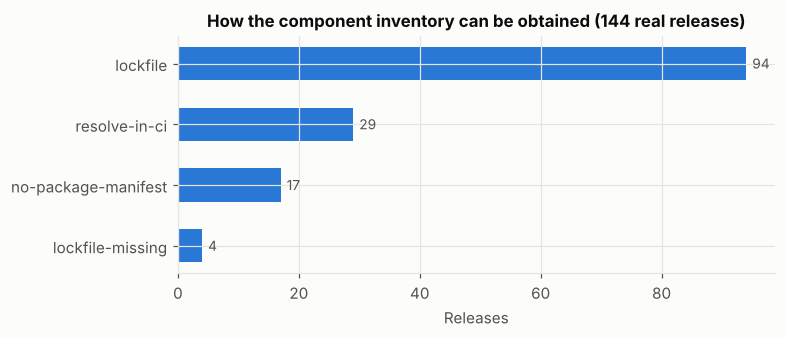

In [3]:
status = cov.inventory_status.str.replace(r' \(.*', '', regex=True).value_counts()
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(status.index[::-1], status.values[::-1], color=plotting.SERIES[0], height=0.55)
for i, v in enumerate(status.values[::-1]): ax.text(v + 1, i, str(v), va='center', fontsize=9, color=plotting.INK2)
ax.set_xlabel('Releases'); ax.set_title('How the component inventory can be obtained (144 real releases)'); plt.show()

**Reading:** about a third of releases have no committed lockfile. For the C/firmware products there is no package manifest at all, so an SBOM is either incomplete or impossible from source. A gate that reads 'no findings' as clean silently passes these releases.

## 2 · Inventory drift between consecutive releases (real data)

In [4]:
rows = []
for pid, g in rel.groupby('product_id'):
    tags = list(g.sort_values('release_date_utc').tag)
    sets = []
    for t in tags:
        f = E9 / 'inventories' / pid / f'{t}.csv'
        d = pd.read_csv(f) if f.exists() and f.stat().st_size > 40 else pd.DataFrame(columns=['ecosystem','name','version','dev'])
        d = d[d.dev.astype(str) != 'True']
        sets.append(set(zip(d.ecosystem, d.name, d.version)))
    for i in range(1, len(sets)):
        u = sets[i-1] | sets[i]
        if u: rows.append({'product_id': pid, 'jaccard': len(sets[i-1] & sets[i]) / len(u), 'changed': len(sets[i] ^ sets[i-1])})
drift = pd.DataFrame(rows)
print('median Jaccard between consecutive quarterly releases:', round(drift.jaccard.median(), 2),
      '| share of transitions changing >10% of components:', round((drift.jaccard < 0.9).mean(), 2))
drift.groupby('product_id').jaccard.median().sort_values().round(2).to_frame('median_jaccard').T

median Jaccard between consecutive quarterly releases: 0.51 | share of transitions changing >10% of components: 0.91


product_id,evcc,home-assistant,esphome,node-red,headscale,zigbee2mqtt,homebridge,influxdb3,telegraf,zwave-js-ui,traefik,adguardhome,frigate
median_jaccard,0.42,0.43,0.43,0.46,0.47,0.51,0.53,0.55,0.55,0.73,0.82,0.87,0.88


**Reading:** most quarterly releases change a large share of their components, so an SBOM or scan from the previous release is stale evidence. This is the empirical basis for binding evidence to the build (recommendation P0-04).

## 3 · Gate decisions on what was knowable at each release date (SYNTHETIC until CI)

In [5]:
m = pd.read_csv(RES / 'release_metrics.csv')
gates = ['gate_none', 'gate_naive_kev', 'gate_cvss7', 'gate_crasme_v1_2']
m['blocker_known_kev'] = m.known_kev > 0
m['unassessable'] = ~m.inventory_ok.astype(bool)
def summarise(g):
    d = m[g]
    return pd.Series({'PASS': (d == 'PASS').mean(), 'REVIEW': (d == 'REVIEW_REQUIRED').mean(), 'FAIL': (d == 'FAIL').mean(),
                      'false_green_on_KEV_releases': ((d == 'PASS') & m.blocker_known_kev).sum() / max(m.blocker_known_kev.sum(), 1),
                      'silent_pass_on_unassessable': ((d == 'PASS') & m.unassessable).sum() / max(m.unassessable.sum(), 1)})
res = pd.DataFrame({g.replace('gate_', ''): summarise(g) for g in gates}).T.round(2)
print('DATA:', 'REAL' if REAL else 'SYNTHETIC'); res

DATA: SYNTHETIC


,PASS,REVIEW,FAIL,false_green_on_KEV_releases,silent_pass_on_unassessable
none,1.00,0.00,0.00,1.0,1.0
naive_kev,0.77,0.00,0.23,0.0,1.0
cvss7,0.74,0.00,0.26,0.0,1.0
crasme_v1_2,0.06,0.94,0.00,0.0,0.0


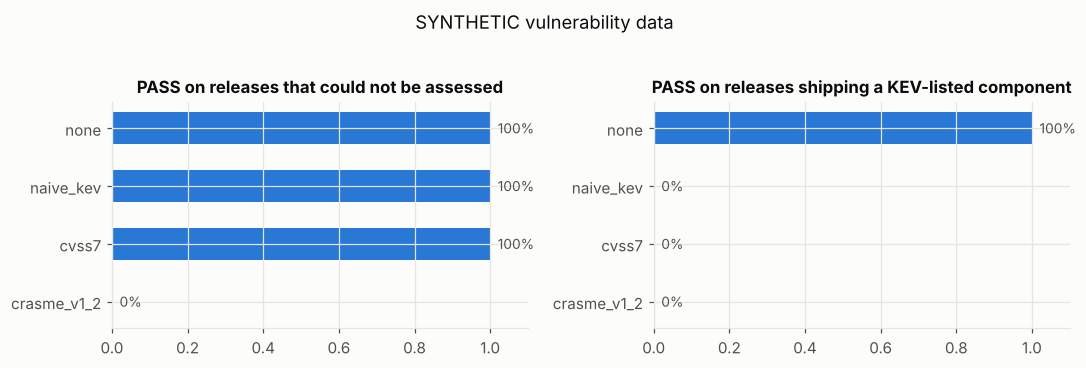

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title in [(axes[0], 'silent_pass_on_unassessable', 'PASS on releases that could not be assessed'),
                       (axes[1], 'false_green_on_KEV_releases', 'PASS on releases shipping a KEV-listed component')]:
    ax.barh(res.index[::-1], res[col][::-1], color=plotting.SERIES[0], height=0.55); ax.set_xlim(0, 1.1); ax.set_title(title)
    for i, v in enumerate(res[col][::-1]): ax.text(v + 0.02, i, f'{v:.0%}', va='center', fontsize=9, color=plotting.INK2)
fig.suptitle(('REAL' if REAL else 'SYNTHETIC') + ' vulnerability data', y=1.03); plt.tight_layout(); plt.show()

## 4 · Exposure windows (vulnerabilities disclosed after a release)

In [7]:
ex = pd.read_csv(RES / 'exposure.csv') if (RES / 'exposure.csv').exists() else pd.DataFrame()
if len(ex):
    ex['days'] = pd.to_numeric(ex.days_published_to_fixed_release, errors='coerce')
    print('disclosed-after-release findings:', len(ex), '| no later sampled release without it:', ex.days.isna().mean().round(2),
          '| median days to a sampled release without it:', ex.days.median())
    display(ex.groupby('product_id').days.describe()[['count', '50%', 'max']].round(0))
else:
    print('no exposure rows')

disclosed-after-release findings: 23 | no later sampled release without it: 0.74 | median days to a sampled release without it: 103.0


,count,50%,max
product_id,,,
evcc,2.0,48.0,48.0
traefik,4.0,126.0,149.0
zigbee2mqtt,0.0,NaN,NaN
zwave-js-ui,0.0,NaN,NaN


## 5 · Head-to-head with OpenCRA (only after the CI run)

In [8]:
op = RES / 'opencra' / 'opencra_probes.csv'
if op.exists():
    display(pd.read_csv(op))
    rr = pd.read_csv(RES / 'opencra' / 'opencra_releases.csv'); display(rr.describe(include='all').T.head())
else:
    print('OpenCRA results not present (they need network: run .github/workflows/e9-replay.yml)')

OpenCRA results not present (they need network: run .github/workflows/e9-replay.yml)


## Threats to validity (summary; full list in the pre-registration)
* **Hindsight in OSV.** Affected ranges are today's knowledge, and `published` can lag the original disclosure.
* **Inventory gap.** A lockfile is not the shipped artefact: it includes dev tooling and misses vendored or C code. The real SBOM-vs-lockfile comparison is reported separately in the CI results (`sbom_vs_lockfile_*.csv`).
* **Coarse exposure windows.** Releases are sampled quarterly, which gives upper bounds only.
* **KEV is not exhaustive.** Absence from KEV is not evidence that a vulnerability was never exploited.
* **Projects are proxies.** The results describe these projects' practices, not CRA compliance of any manufacturer.